Today's topics:
* color as a third variable
* contour maps with `tricontourf`
* interactive 2D and 3D scatter plots with Plotly Express

# 3D printed parts

Today we will add a third variable to a plot.
We'll start with color.
Then we'll draw a contour map.
Last, we'll make plots we can rotate.

A [fused deposition](https://en.wikipedia.org/wiki/Fused_filament_fabrication) printer melts a plastic filament and lays it down one bead at a time.
The printer builds the part layer by layer.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/a/ad/RepRap_printing_closeup.jpg/960px-RepRap_printing_closeup.jpg" alt="Close-up of a fused-deposition printer in operation, with a brass nozzle above three red parts whose deposited layers are visible" width=520/>

*Photo by Emmanuel Gilloz, [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:RepRap_printing_closeup.jpg).*

Above: the horizontal lines on the parts are the deposited layers.

The table records nine printer settings and three measured outcomes.
We'll focus on two settings today.
- `layer_height (mm)` is the height of one bead
- `wall_thickness (mm)` is the thickness of the outer shell

Each finished part has a measured side-wall `roughness (microns)` and a `tension_strength (Mpa)` from a tensile test.

We'll use 50 prints from [Ahmet Okudan's 3D printer dataset](https://github.com/ahmetokudan/3dprinterdeeplearning), released into the public domain.
These come from a different study than the printed-part compression test.

Both outcomes vary with several settings at once.
Which combinations go with smoother, stronger parts in this table?

A plot has two axes, so how do we show a third setting?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/3dprinting.csv'
data = pd.read_csv(url)
print(len(data), 'prints')

50 prints


Let's give the columns we need short names.

In [2]:
layer = data['layer_height (mm)']
wall = data['wall_thickness (mm)']
nozzle = data['nozzle_temperature (degC)']
rough = data['roughness (microns)']

We'll start with a plot we know: roughness against layer height.

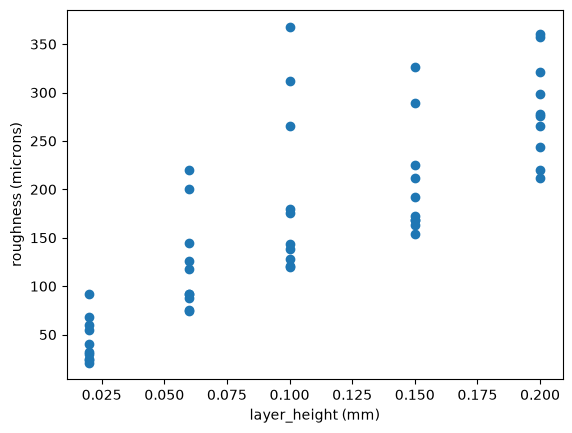

In [3]:
fig, ax = plt.subplots()
ax.scatter(layer, rough)
ax.set_xlabel(layer.name)
ax.set_ylabel(rough.name)
plt.show()

Roughness rises with layer height.
Where does wall thickness fit in?

# Color as a third variable

## One series per value

We already know one way to add a third variable.
We draw a separate series for each value and label it.

Wall thickness takes ten values, so let's list them and loop over the list with a mask.

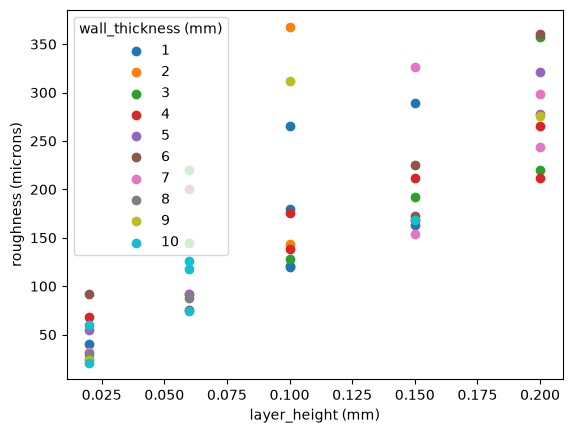

In [4]:
walls = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]  # mm

fig, ax = plt.subplots()
for thickness in walls:
    mask = wall == thickness  # True for prints with this wall
    ax.scatter(layer.loc[mask], rough.loc[mask], label=thickness)
ax.set_xlabel(layer.name)
ax.set_ylabel(rough.name)
ax.legend(title=wall.name)
plt.show()

Wall thickness runs from 1 to 10 mm, so let's encode that order with a color scale.

## The `c` keyword

`ax.scatter` takes a keyword `c` for the color of each marker.
We give it one number per print, here the wall thickness.

The keyword `cmap` sets the **colormap**, the scale that turns numbers into colors.
`'viridis'` runs from dark purple at the lowest value to yellow at the highest.
It reads well for colorblind viewers, and it still runs dark to light in a greyscale printout.

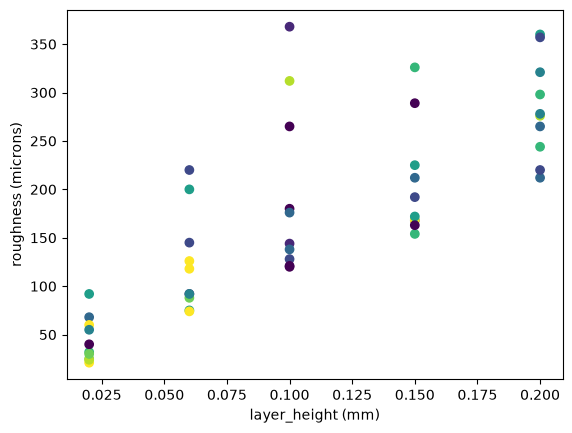

In [5]:
fig, ax = plt.subplots()
ax.scatter(layer, rough, c=wall, cmap='viridis')  # c: one number per print
ax.set_xlabel(layer.name)
ax.set_ylabel(rough.name)
plt.show()

## A colorbar

A **colorbar** pairs each color with a number.
`ax.scatter` returns the object that stores the colormap and the range of values, so let's save it as `im` and pass it to `fig.colorbar`.

The colorbar is an object too, and its `set_label` method works like `ax.set_xlabel`.

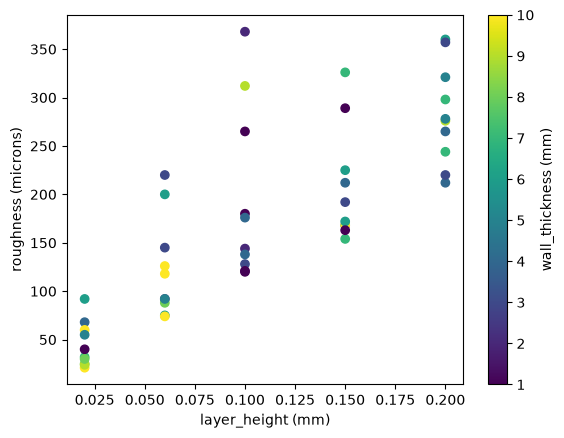

In [6]:
fig, ax = plt.subplots()
im = ax.scatter(layer, rough, c=wall, cmap='viridis')
cb = fig.colorbar(im, ax=ax)  # ax is the axes that gets the bar
cb.set_label(wall.name)
ax.set_xlabel(layer.name)
ax.set_ylabel(rough.name)
plt.show()

> We'll use `fig.colorbar(im, ax=ax)` so the call names the axes that owns the colorbar.

Roughness climbs with layer height, and the colors are mixed at every layer height.

### [Check your understanding]

Let's see which settings go with a strong part.

1. Plot wall thickness against infill density, with each print colored by its tension strength.
2. Make the plot readable on its own: a reader should know what each axis and each color means.
3. Find the strongest prints. What infill density and wall thickness do they have?
4. Does strength follow either setting closely, or are strong and weak prints mixed together?

# Contour maps

Color shows a value at each print.
For an outcome like roughness, we may want a value at every combination of the two settings.

A topographic map does this for land.
Each line joins points of equal elevation, and where lines bunch together the ground is steep.

A **contour** map does the same for any quantity.
Our two axes are the settings, and the elevation is roughness.

`ax.tricontourf` takes three columns of the same length: `x`, `y`, and the value `z`.
The `f` stands for filled.

It joins the prints into triangles and interpolates `z` across each triangle.
Then it fills a band of color for each range of `z`.

Like `ax.scatter`, `ax.tricontourf` returns an object that `fig.colorbar` can use.

We'll draw the 50 prints on top with the same colormap.
Each marker would vanish into a band of its own color, so `edgecolor='k'` outlines every marker in black.

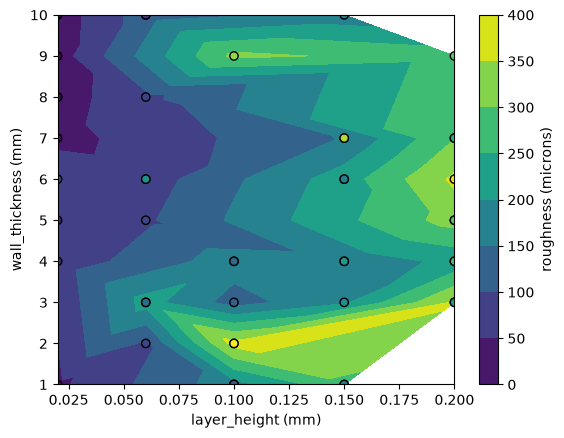

In [7]:
fig, ax = plt.subplots()
cs = ax.tricontourf(layer, wall, rough, cmap='viridis')  # filled bands
ax.scatter(layer, wall, c=rough, cmap='viridis', edgecolor='k')  # the prints
cb = fig.colorbar(cs, ax=ax)
cb.set_label(rough.name)
ax.set_xlabel(layer.name)
ax.set_ylabel(wall.name)
plt.show()

Neighboring bands have similar colors, so the levels are hard to tell apart.
`ax.tricontour` draws only the lines between bands.
Let's add thin black lines at the band edges.

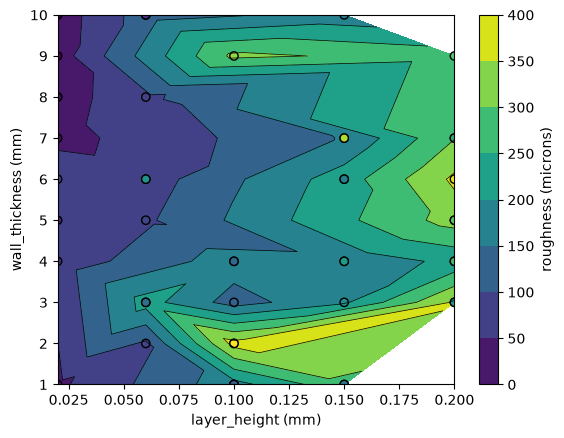

In [8]:
fig, ax = plt.subplots()
cs = ax.tricontourf(layer, wall, rough, cmap='viridis')  # filled bands
ax.tricontour(layer, wall, rough, colors='k', linewidths=0.5)  # band edges
ax.scatter(layer, wall, c=rough, cmap='viridis', edgecolor='k')  # the prints
cb = fig.colorbar(cs, ax=ax)
cb.set_label(rough.name)
ax.set_xlabel(layer.name)
ax.set_ylabel(wall.name)
plt.show()

The lines run mostly up and down, with some bends.
Roughness changes mainly as we move along the layer height axis, and much less as we move up the wall thickness axis.

Most markers match the band behind them, and a few don't.

## Where a marker and the map differ

The map comes from triangles between the sampled locations, so it's an interpolation.
At a location we sampled twice, there are two measured values and the map shows one.

Let's look at the prints made at a layer height of 0.1 mm and a wall thickness of 1 mm.
We join the two comparisons with `&`.

In [9]:
same = (layer == 0.1) & (wall == 1)  # & joins the two comparisons
print(data.loc[same, ['material', nozzle.name, rough.name]])

   material  nozzle_temperature (degC)  roughness (microns)
20      abs                        220                  120
22      abs                        230                  265
25      pla                        200                  180
29      pla                        220                  121


Four prints share the same two settings and differ in the others, and their roughness differs too.
A map of two settings has one value at each location, while these four prints have four different roughness values.

### [Check your understanding]

Let's try a different second setting.
The cell below draws a filled contour map of roughness over layer height and nozzle temperature.

1. Label the axes.
2. Show the 50 prints on the map, colored by their measured roughness, so each one stands out from the band behind it.
3. Make the edges between bands easy to see.
4. Across these sampled ranges, does roughness change more with layer height or with nozzle temperature? How do the band edges show it?

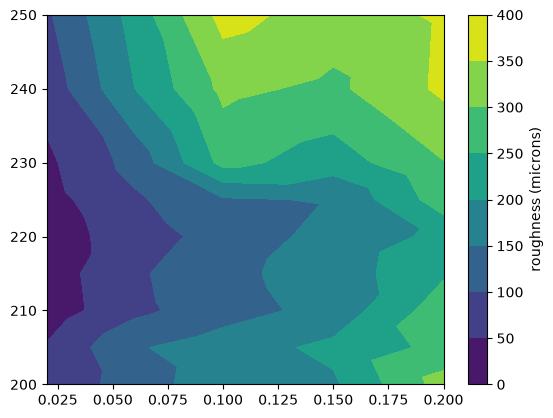

In [10]:
fig, ax = plt.subplots()
cs = ax.tricontourf(layer, nozzle, rough, cmap='viridis')
cb = fig.colorbar(cs, ax=ax)
cb.set_label(rough.name)

# Interactive plots with Plotly Express

Our Matplotlib plots are still images.
[Plotly](https://plotly.com/python/) draws plots we can zoom, rotate, and hover over.
Its simplest interface is **Plotly Express**, which we import as `px`.

`px.scatter` takes the same columns as `ax.scatter`.
`color` plays the role of `c`, and `color_continuous_scale` plays the role of `cmap`.
The `labels` dictionary names the axes and the colorbar, like `ax.set_xlabel` and `cb.set_label`.

In [11]:
import plotly.express as px

px.scatter(x=layer,
           y=rough,
           color=wall,  # like c=
           color_continuous_scale='viridis',  # like cmap=
           labels={'x': layer.name,  # axis and colorbar labels
                   'y': rough.name,
                   'color': wall.name})

Hover over a marker to read its values.
Drag a box to zoom in, and double-click to zoom back out.

## A third axis

`px.scatter_3d` takes a third column `z`, so the third variable gets its own axis.
We'll put roughness on the vertical axis and color by it too.

In [12]:
px.scatter_3d(x=layer,
              y=wall,
              z=rough,
              color=rough,
              color_continuous_scale='viridis',
              labels={'x': layer.name,
                      'y': wall.name,
                      'z': rough.name,
                      'color': rough.name})

Drag to rotate the plot.

Look along the wall thickness axis, and roughness rises with layer height.
Look along the layer height axis, and roughness changes much less with wall thickness.
The contour map showed the same pattern with lines that run mostly up and down.

## The DataFrame interface

`px` can also take the whole DataFrame, then the column names as strings.
Plotly reads the labels from the column names, so we don't need `labels`.
Without `color_continuous_scale`, Plotly uses its default colormap.
The points are the same as above, and only the colors change.

In [13]:
px.scatter_3d(data,
              x='layer_height (mm)',
              y='wall_thickness (mm)',
              z='roughness (microns)',
              color='roughness (microns)')

On a screen, we can turn a 3D plot until the pattern shows.
On a printed page, we get only one view, so color and contours still matter.

# Summary

* `c=` gives `ax.scatter` one number per marker, and `cmap` turns the numbers into colors.
* `im = ax.scatter(...)` saves the object that `fig.colorbar(im, ax=ax)` needs, and `cb.set_label` names the scale.
* `ax.tricontourf(x, y, z)` fills bands of equal `z` across the plane of two variables.
* `tricontourf` interpolates between the sampled points.
* Plotly Express `px.scatter` and `px.scatter_3d` draw plots we can zoom, rotate, and hover over.
* `px` takes columns like `ax.scatter` does, or a whole DataFrame and its column names.

## Further reading

* VanderPlas, *Python Data Science Handbook*, [Simple Scatter Plots](https://jakevdp.github.io/PythonDataScienceHandbook/04.02-simple-scatter-plots.html), for `c`, `s`, and a colorbar on a scatter plot
* VanderPlas, *Python Data Science Handbook*, [Density and Contour Plots](https://jakevdp.github.io/PythonDataScienceHandbook/04.04-density-and-contour-plots.html), for contours of a function on a regular grid
* VanderPlas, *Python Data Science Handbook*, [Customizing Colorbars](https://jakevdp.github.io/PythonDataScienceHandbook/04.07-customizing-colorbars.html), for choosing a colormap
* Kong, Siauw, and Bayen, *Python Programming and Numerical Methods*, [12.2 "3D Plotting"](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter12.02-3D-Plotting.html), for 3D plots in Matplotlib
* [`matplotlib.axes.Axes.tricontourf` documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.tricontourf.html)
* [Choosing colormaps in Matplotlib](https://matplotlib.org/stable/users/explain/colors/colormaps.html)
* [Plotly Express scatter plots](https://plotly.com/python/line-and-scatter/) and [3D scatter plots](https://plotly.com/python/3d-scatter-plots/)

# Appendix A: Marker size and other colormaps

Optional.

The keyword `s` sets the size of each marker, so it can show a fourth variable.
Here the size follows wall thickness, and the color follows tension strength.

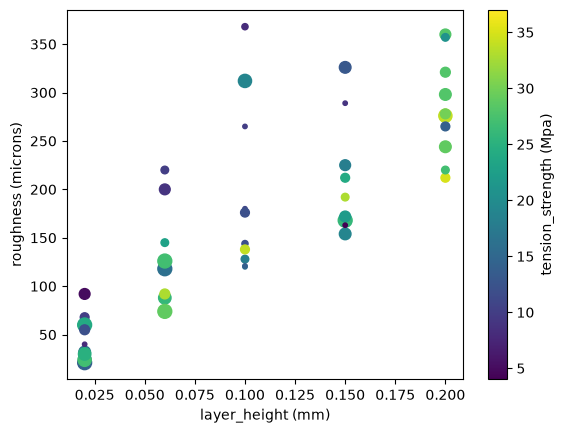

In [14]:
strength = data['tension_strength (Mpa)']

size = 10 * wall  # marker area in points squared

fig, ax = plt.subplots()
im = ax.scatter(layer, rough, s=size, c=strength, cmap='viridis')
cb = fig.colorbar(im, ax=ax)
cb.set_label(strength.name)
ax.set_xlabel(layer.name)
ax.set_ylabel(rough.name)
plt.show()

Marker size is hard to compare across a plot, so I use it sparingly.

Matplotlib has many other colormaps.
`'Greys'` runs from white at the lowest value to black at the highest.
Here is the same plot with it.

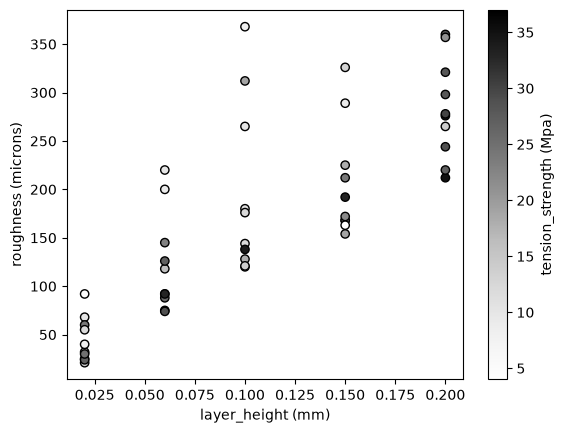

In [15]:
fig, ax = plt.subplots()
im = ax.scatter(layer, rough, c=strength, cmap='Greys', edgecolor='k')
cb = fig.colorbar(im, ax=ax)
cb.set_label(strength.name)
ax.set_xlabel(layer.name)
ax.set_ylabel(rough.name)
plt.show()

When marker color represents a number, add a colorbar so readers can decode it.

# Appendix B: Saving a Plotly plot as a web page

Optional.

A Plotly figure can be saved as an HTML file, the format of a web page.
The file holds the data and the code that draws the plot, so it opens in any web browser without Python.

Let's draw the 3D scatter again and save it with `fig.write_html`.

In [16]:
fig = px.scatter_3d(data,
                    x='layer_height (mm)',
                    y='wall_thickness (mm)',
                    z='roughness (microns)',
                    color='roughness (microns)')
fig.write_html('roughness_3d.html')  # saves the interactive plot

The file `roughness_3d.html` appears in the Colab file browser on the left.
Download it and send it to someone, and they can rotate the plot in their browser.